In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%pip install neuralforecast
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, LSTM

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.0/294.0 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 831.6/831.6 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 57.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd

from google.colab import files
uploaded = files.upload()

Saving usd_idr_2020_2026.xlsx to usd_idr_2020_2026.xlsx


In [ ]:
data = pd.read_excel('usd_idr_2020_2026.xlsx',sheet_name="Sheet2",header = 0)
data = data[['ds', 'y', 'unique_id']]
data.head()

,ds,y,unique_id
0,2017-01-02,13512.0,IDR=X
1,2017-01-03,13506.0,IDR=X
2,2017-01-04,13443.0,IDR=X
3,2017-01-05,13348.0,IDR=X
4,2017-01-06,13319.0,IDR=X


In [ ]:
data['ds'] = pd.to_datetime(data['ds'])

train_df = data[data['ds'] < '2025-07-04']
test_df  = data[data['ds'] >= '2025-07-04']

# **Membangun Model**

In [ ]:
horizon = len(test_df)

model = LSTM(
    h = horizon,
    input_size = 42,
    encoder_n_layers = 4,
    decoder_layers = 4,
    encoder_hidden_size = 500,
    decoder_hidden_size = 500,
    max_steps = 100,
    learning_rate = 0.0005,
    scaler_type="minmax",
)

INFO:lightning_fabric.utilities.seed:Seed set to 1


In [ ]:
horizon

151

# **Melatih Model**

In [ ]:
nf = NeuralForecast(
    models=[model],
    freq='B'
)

Y_hat_df = nf.fit(df=train_df, val_size=horizon)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.callbacks.model_summary:
  | Name              | Type          | Params | Mode 
------------------------------------------------------------
0 | loss              | MAE           | 0      | train
1 | padder_train      | ConstantPad1d | 0      | train
2 | scaler            | TemporalNorm  | 0      | train
3 | hist_encoder      | LSTM          | 7.0 M  | train
4 | mlp_decoder       | MLP           | 752 K  | train
5 | upsample_sequence | Linear        | 6.5 K  | train
------------------------------------------------------------
7.8 M     Trainable params
0         Non-trainable params
7.8 M     Total params
31.106    Total estimated model params size (MB)
15        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=100` reached.


# **Prediksi Data Latih**

In [ ]:
pred_train = nf.predict_insample()

pred_train_pick = (
    pred_train
    .groupby(['unique_id', 'ds'])['LSTM']
    .last()
    .reset_index()
)

train_with_pred = train_df.merge(
    pred_train_pick,
    on=['unique_id', 'ds'],
    how='left'
)


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

In [ ]:
train_with_pred

,ds,y,unique_id,LSTM
0,2017-01-02,13512.000000,IDR=X,-inf
1,2017-01-03,13506.000000,IDR=X,1.351258e+04
2,2017-01-04,13443.000000,IDR=X,1.350947e+04
3,2017-01-05,13348.000000,IDR=X,1.348350e+04
4,2017-01-06,13319.000000,IDR=X,1.344365e+04
...,...,...,...,...
2214,2025-06-27,16222.799805,IDR=X,1.597898e+04
2215,2025-06-30,16229.000000,IDR=X,1.596108e+04
2216,2025-07-01,16230.000000,IDR=X,1.598106e+04
2217,2025-07-02,16236.400391,IDR=X,1.598395e+04


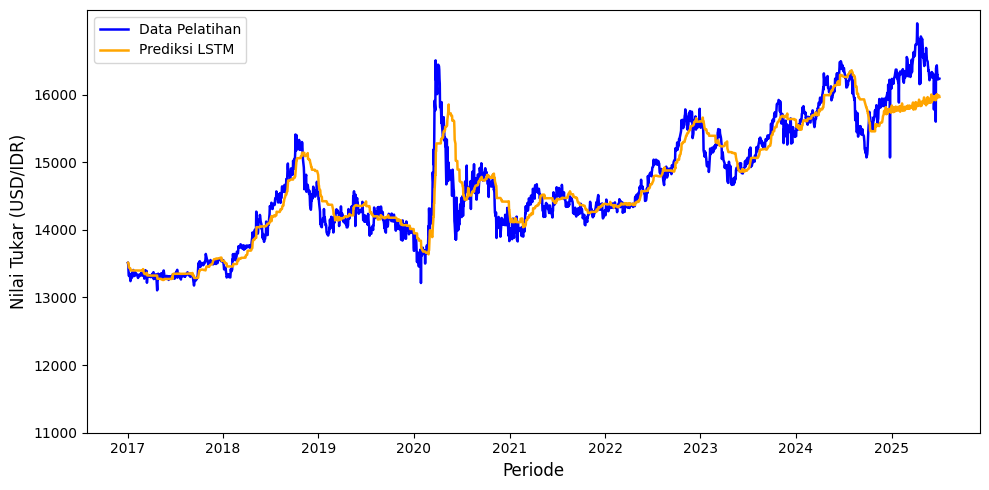

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

plt.plot(train_with_pred['ds'], train_with_pred['y'],
         color='blue',
         linewidth=1.8,
         label='Data Pelatihan')

plt.plot(train_with_pred['ds'], train_with_pred['LSTM'],
         color='orange',
         linewidth=1.8,
         label='Prediksi LSTM')

plt.xlabel('Periode', fontsize=12)
plt.ylabel('Nilai Tukar (USD/IDR)', fontsize=12)
plt.yticks(np.arange(11000, 17000, 1000))

plt.grid(False)
plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
from neuralforecast.losses.numpy import mape

print(
    'MAPE Train:',
    mape(
        train_with_pred['y'].iloc[1:],
        train_with_pred['LSTM'].iloc[1:]
    )
)

MAPE Train: 0.012751452824419312


In [ ]:
import numpy as np

print('Korelasi Pearson Train:', np.corrcoef(train_with_pred.replace([np.inf, -np.inf], np.nan).dropna()[['y', 'LSTM']].T)[0, 1])

Korelasi Pearson Train: 0.9487977347685964


# **Prediksi Data Uji**

In [ ]:
fcst = nf.predict(h=horizon)
fcst

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

,unique_id,ds,LSTM
0,IDR=X,2025-07-04,16222.758789
1,IDR=X,2025-07-07,16179.497070
2,IDR=X,2025-07-08,16194.413086
3,IDR=X,2025-07-09,16192.376953
4,IDR=X,2025-07-10,16242.046875
...,...,...,...
146,IDR=X,2026-01-26,16553.349609
147,IDR=X,2026-01-27,16571.103516
148,IDR=X,2026-01-28,16558.544922
149,IDR=X,2026-01-29,16580.826172


In [ ]:
result = pd.concat([
    test_df[['ds','y']].reset_index(drop=True),
    fcst[['LSTM']].reset_index(drop=True)
], axis=1)

print(result)
print(result.columns)

            ds             y          LSTM
0   2025-07-04  16203.700195  16222.758789
1   2025-07-07  16178.000000  16179.497070
2   2025-07-08  16318.900391  16194.413086
3   2025-07-09  16261.000000  16192.376953
4   2025-07-10  16235.000000  16242.046875
..         ...           ...           ...
146 2026-01-26  16770.000000  16553.349609
147 2026-01-27  16734.000000  16571.103516
148 2026-01-28  16674.699219  16558.544922
149 2026-01-29  16722.800781  16580.826172
150 2026-01-30  16778.300781  16540.369141

[151 rows x 3 columns]
Index(['ds', 'y', 'LSTM'], dtype='object')


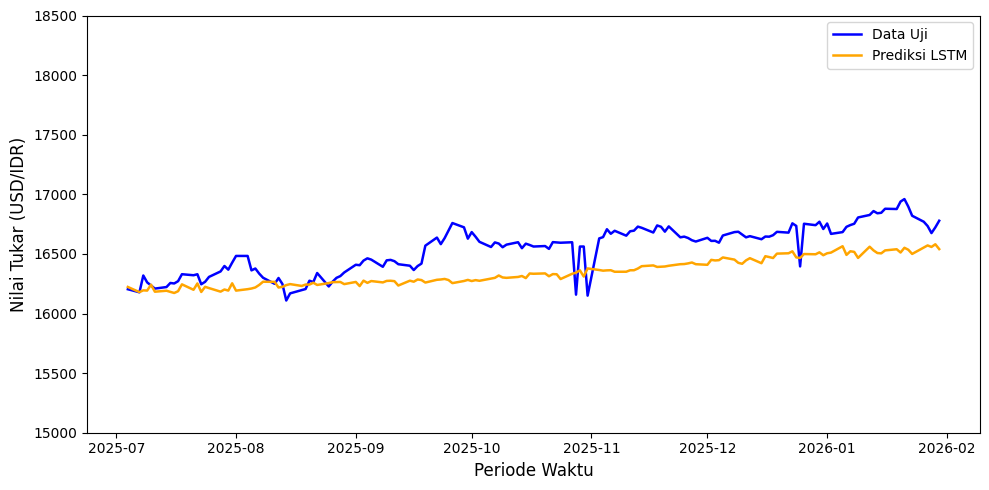

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(result['ds'], result['y'],
         color='blue',
         linewidth=1.8,
         label='Data Uji')

plt.plot(result['ds'], result['LSTM'],
         color='orange',
         linewidth=1.8,
         label='Prediksi LSTM')

plt.xlabel('Periode Waktu', fontsize=12)
plt.ylabel('Nilai Tukar (USD/IDR)', fontsize=12)
plt.yticks(np.arange(15000, 19000, 500))
plt.grid(False)
plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
import numpy as np
from neuralforecast.losses.numpy import mape

print('MAPE Test:', mape(result['y'], result['LSTM']))

MAPE Test: 0.012417764802188182


In [ ]:
import numpy as np

print('Korelasi Pearson Test:', np.corrcoef(result['y'], result['LSTM'])[0, 1])

Korelasi Pearson Test: 0.8022549369791021


# **Peramalan 7 Bulan Ke Depan**

In [ ]:
nf_final = NeuralForecast(
    models=[model],
    freq='B'
)

Y_hat_df_final = nf_final.fit(df=data, val_size=horizon)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.callbacks.model_summary:
  | Name              | Type          | Params | Mode 
------------------------------------------------------------
0 | loss              | MAE           | 0      | train
1 | padder_train      | ConstantPad1d | 0      | train
2 | scaler            | TemporalNorm  | 0      | train
3 | hist_encoder      | LSTM          | 7.0 M  | train
4 | mlp_decoder       | MLP           | 752 K  | train
5 | upsample_sequence | Linear        | 6.5 K  | train
------------------------------------------------------------
7.8 M     Trainable params
0         Non-trainable params
7.8 M     Total params
31.106    Total estimated model params size (MB)
15        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=100` reached.


In [ ]:
fcst_future = nf_final.predict(data, h=horizon)
fcst_future

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

,unique_id,ds,LSTM
0,IDR=X,2026-02-02,16750.556641
1,IDR=X,2026-02-03,16724.066406
2,IDR=X,2026-02-04,16710.710938
3,IDR=X,2026-02-05,16702.236328
4,IDR=X,2026-02-06,16755.476562
...,...,...,...
146,IDR=X,2026-08-25,16925.875000
147,IDR=X,2026-08-26,16927.222656
148,IDR=X,2026-08-27,16921.693359
149,IDR=X,2026-08-28,16900.964844


In [ ]:
data_ftr = pd.read_excel('usd_idr_2020_2026.xlsx',sheet_name="Sheet5",header = 0)
data_ftr = data_ftr[['ds', 'y', 'unique_id']]
data_ftr.head()

,ds,y,unique_id
0,2026-02-02,16758.400391,IDR=X
1,2026-02-03,16758.400391,IDR=X
2,2026-02-04,16759.000000,IDR=X
3,2026-02-05,16800.000000,IDR=X
4,2026-02-06,16879.900391,IDR=X


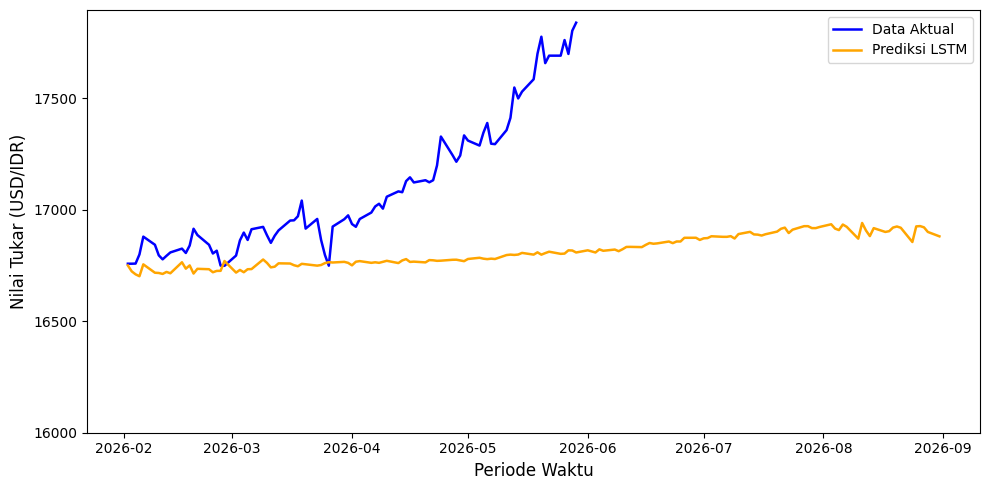

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(data_ftr['ds'], data_ftr['y'],
         color='blue',
         linewidth=1.8,
         label='Data Aktual')

plt.plot(fcst_future['ds'], fcst_future['LSTM'],
         color='orange',
         linewidth=1.8,
         label='Prediksi LSTM')

plt.xlabel('Periode Waktu', fontsize=12)
plt.ylabel('Nilai Tukar (USD/IDR)', fontsize=12)
plt.yticks(np.arange(16000, 18000, 500))
plt.grid(False)
plt.legend()

plt.tight_layout()

plt.show()